# AR waveguide combiners: k-space, gratings and the eye box

Augmented reality glasses have to put a bright image in front of the eye
without blocking the view of the world. The solution in most current
glasses (HoloLens, Magic Leap, many smaller designs) is a **waveguide
combiner**: a glass plate a millimetre or less thick, with a small
projector at its edge. A grating (the **in-coupler**) bends the image light
so steeply into the plate that it is trapped by total internal
reflection; it travels sideways, and a second, weak grating (the
**out-coupler**) lets a little of it out towards the eye at every bounce.
Each bounce makes another copy of the small projector pupil, so the eye
can move within a box of a centimetre or more and still see the image:
**exit pupil expansion**. The world is seen straight through the plate.

This notebook builds the combiner from what the earlier notebooks provide:
the grating equation in vector form, total internal reflection
(notebook 10, interfaces and thin films), rigorous
grating efficiencies with RCWA
(notebooks 36 (rigorous mask) and
110 (grating and prism spectrometers))
and real glass data (notebook 61, glass catalogues).
The sections are:

1. k-space: why the field of view is set by the index of the glass,
2. colour: one plate per primary,
3. the in-coupler computed with RCWA: binary against slanted gratings,
4. the out-coupler and the eye box: replicated pupils, graded
   efficiency, the thickness of the plate and the stripes it causes,
5. the rainbow artefact: lamps and the sky seen through the out-coupler,
6. two-dimensional pupil expansion with a fold grating.

The volume holographic gratings used in some combiners are the subject of
notebook 124 (volume holographic gratings).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import arvr
from pyoptics import glasses
from pyoptics import sketch
from pyoptics.litho.rcwa import rcwa

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
RGB = {460.0: "#3b5bdb", 530.0: "#2f9e44", 630.0: "#e03131"}
t_start = time.time()

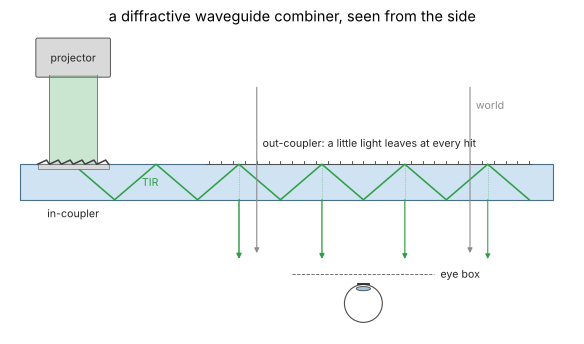

In [2]:
fig, ax = plt.subplots(figsize=(13, 5))
with sketch.text_scale(1.2):
    sketch.waveguide_combiner(ax, "side", title="a diffractive waveguide combiner, seen from the side")
plt.show()

## 1. k-space and the field of view

Every point of the projected image is a plane wave with its own direction,
the **field angle**. What matters for a plate is its transverse wave
vector, in units of $k_0 = 2\pi/\lambda$,

$$\mathbf k = (k_x, k_y) = n\,(\sin\theta\cos\phi, \sin\theta\sin\phi),$$

because it is conserved at every plane interface (Snell's law is
$n_1\sin\theta_1 = n_2\sin\theta_2$, i.e. $\mathbf k$ unchanged). In air
$|\mathbf k| \le 1$; in glass of index $n$ the light can have
$|\mathbf k| \le n$, and if $|\mathbf k| > 1$ it cannot leave into air:
it is trapped by **total internal reflection**. A grating with period
$\Lambda$ and grooves perpendicular to the unit vector $\hat{\mathbf g}$
adds $m\lambda/\Lambda\,\hat{\mathbf g}$ to $\mathbf k$ (the grating
equation in vector form, `arvr.diffract()`).

So the image, a rectangle of field angles around $\mathbf k = 0$, has to
be shifted by the in-coupler into the **annulus**
$1 < |\mathbf k| < n\sin\theta_\mathrm{max}$, where it is guided. The
upper limit is not $n$: a wave at 89° bounces once per many centimetres
and leaves gaps in the eye box (section 4); practical designs stop near
$\theta_\mathrm{max} = 75°$. The out-coupler subtracts the same vector and
returns the image to where it was. Along the grating vector, the field of
view therefore fits only if

$$2\sin(\mathrm{FOV}/2) \le n\sin\theta_\mathrm{max} - 1,$$

which is `arvr.max_fov_1d()`. The index of the plate is the single most
important number of a waveguide combiner, which is why glass makers sell
special high-index wafers for it. Below, the guided region for the indices
of four real glasses of the SCHOTT catalogue at 530 nm, and a 40° × 24°
field of view (16:9-ish, 46° diagonal) moved by the symmetric period
$\lambda/\Lambda = (1 + n\sin\theta_\mathrm{max})/2$.

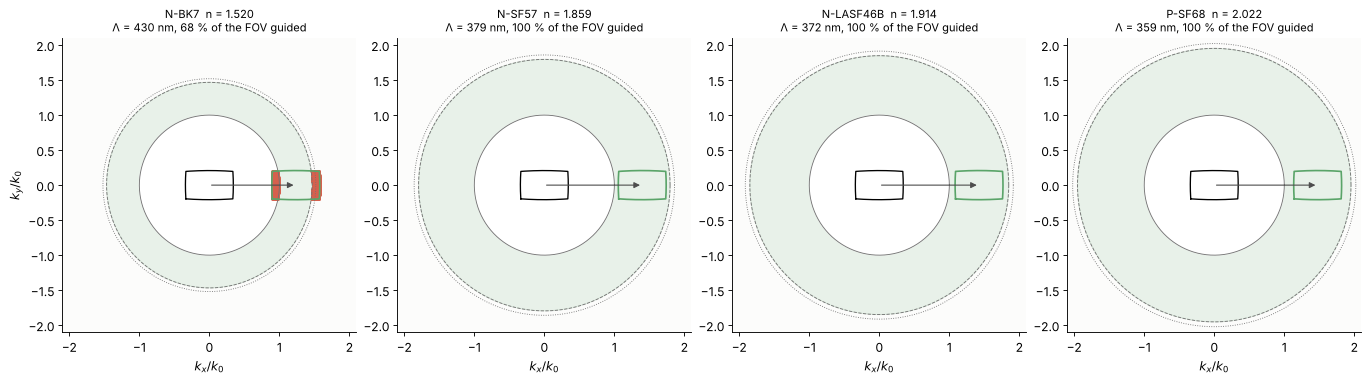

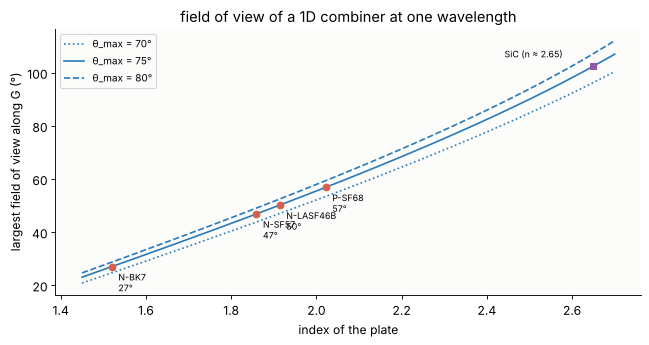

N-BK7      n = 1.5196: 1D FOV  27.1°, period 430 nm
N-SF57     n = 1.8589: 1D FOV  46.9°, period 379 nm
N-LASF46B  n = 1.9136: 1D FOV  50.2°, period 372 nm
P-SF68     n = 2.0217: 1D FOV  56.9°, period 359 nm


In [3]:
LAM = 530.0                         # nm, green
THETA_MAX = np.radians(75.0)
GLASS_NAMES = ["N-BK7", "N-SF57", "N-LASF46B", "P-SF68"]
n_glass = {g: float(glasses.get(g)(LAM)) for g in GLASS_NAMES}
HFOV, VFOV = np.radians(40.0), np.radians(24.0)


def fov_box(hfov, vfov, n=60):
    """Outline of the field of view in k-space (air)."""
    tx = np.r_[np.linspace(-1, 1, n), np.ones(n), np.linspace(1, -1, n), -np.ones(n)]*hfov/2
    ty = np.r_[-np.ones(n), np.linspace(-1, 1, n), np.ones(n), np.linspace(1, -1, n)]*vfov/2
    return arvr.field_to_k(tx, ty)


tx_g, ty_g = np.meshgrid(np.linspace(-HFOV/2, HFOV/2, 81), np.linspace(-VFOV/2, VFOV/2, 49))
kx_g, ky_g = arvr.field_to_k(tx_g, ty_g)
phi = np.linspace(0, 2*np.pi, 400)
fig, axs = plt.subplots(1, 4, figsize=(17, 4.6), layout="constrained")
for ax, g in zip(axs, GLASS_NAMES):
    n = n_glass[g]
    P = arvr.symmetric_period(n, LAM)
    ax.fill(n*np.sin(THETA_MAX)*np.cos(phi), n*np.sin(THETA_MAX)*np.sin(phi), color=GREEN, alpha=0.12)
    ax.fill(np.cos(phi), np.sin(phi), color="white")
    for r, ls in ((1.0, "-"), (n*np.sin(THETA_MAX), "--"), (n, ":")):
        ax.plot(r*np.cos(phi), r*np.sin(phi), color=GREY, lw=0.8, ls=ls)
    bx, by = fov_box(HFOV, VFOV)
    ax.plot(bx, by, color="k", lw=1.2)
    cx, cy = arvr.diffract(bx, by, P, LAM)
    ax.plot(cx, cy, color=GREEN, lw=1.5)
    gx, gy = arvr.diffract(kx_g, ky_g, P, LAM)
    ok = arvr.is_guided(gx, gy, n, THETA_MAX)
    ax.scatter(gx[~ok], gy[~ok], s=2, color=RED)
    ax.annotate("", xy=(LAM/P, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="0.3"))
    ax.set_aspect("equal")
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-2.1, 2.1)
    ax.set_title("{}  n = {:.3f}\nΛ = {:.0f} nm, {:.0f} % of the FOV guided".format(
        g, n, P, 100*ok.mean()), fontsize=10)
    ax.set_xlabel("$k_x/k_0$")
axs[0].set_ylabel("$k_y/k_0$")
plt.show()

n_range = np.linspace(1.45, 2.7, 200)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for tm, ls in ((70, ":"), (75, "-"), (80, "--")):
    ax.plot(n_range, np.degrees(arvr.max_fov_1d(n_range, np.radians(tm))), color=BLUE, ls=ls,
            label="θ_max = {}°".format(tm))
for g in GLASS_NAMES:
    f = np.degrees(arvr.max_fov_1d(n_glass[g], THETA_MAX))
    ax.plot(n_glass[g], f, "o", color=RED)
    ax.annotate("{}\n{:.0f}°".format(g, f), (n_glass[g], f), textcoords="offset points",
                xytext=(6, -22), fontsize=8)
ax.plot(2.65, np.degrees(arvr.max_fov_1d(2.65, THETA_MAX)), "s", color=PURPLE)
ax.annotate("SiC (n ≈ 2.65)", (2.65, np.degrees(arvr.max_fov_1d(2.65, THETA_MAX))),
            textcoords="offset points", xytext=(-80, 8), fontsize=8)
ax.set_xlabel("index of the plate")
ax.set_ylabel("largest field of view along G (°)")
ax.set_title("field of view of a 1D combiner at one wavelength")
ax.legend(fontsize=9)
plt.show()
for g in GLASS_NAMES:
    print("{:10s} n = {:.4f}: 1D FOV {:5.1f}°, period {:.0f} nm".format(
        g, n_glass[g], np.degrees(arvr.max_fov_1d(n_glass[g], THETA_MAX)),
        arvr.symmetric_period(n_glass[g], LAM)))

The index sets the field of view. N-BK7 guides only 68 % of a
40° × 24° field: its annulus is too narrow, and the red dots mark the
fields that hit the TIR circle on the left or run beyond
$n\sin\theta_\mathrm{max}$ on the right. From $n \approx 1.86$ on, the
whole field fits. The 1D limit grows from 27° for N-BK7 to 57° for P-SF68,
and silicon carbide ($n \approx 2.65$) reaches about 100° along the
grating vector, which is why high-index glass wafers and SiC are the
substrates of current wide-field designs. The period shrinks with the
index, from 430 nm to 360 nm, well below the wavelength: these are
subwavelength gratings made by nanoimprint, not by ruling.

## 2. Colour: one plate per primary

The grating vector $\lambda/\Lambda$ grows with the wavelength. A plate
designed for green moves the field of view of blue light too little
(towards the TIR circle, where the fields fall out of the guide) and that
of red light too far (beyond $\theta_\mathrm{max}$, or beyond $n$). The
same plate cannot carry the full field in all three colours unless the
field is small, which is why many combiners stack two or three plates,
each with its own period, and why the colour uniformity of single-plate
designs suffers. Below, the 40° × 24° field in the N-LASF46B plate
designed for 530 nm, for the three primaries of a typical projector.

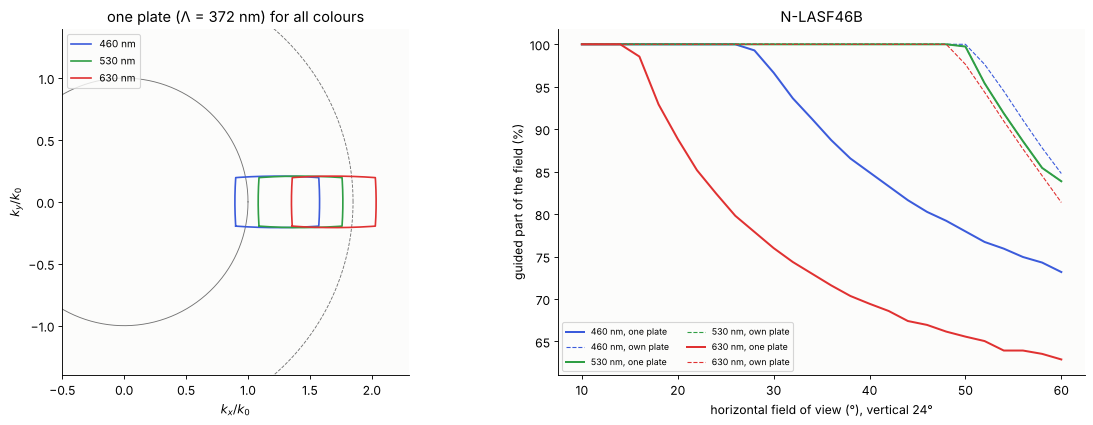

460 nm: n = 1.9322, one plate guides 85 % of 40° x 24°, own period 321 nm
530 nm: n = 1.9136, one plate guides 100 % of 40° x 24°, own period 372 nm
630 nm: n = 1.8981, one plate guides 70 % of 40° x 24°, own period 445 nm


In [4]:
n_rgb = {lam: float(glasses.get("N-LASF46B")(lam)) for lam in RGB}
P_green = arvr.symmetric_period(n_glass["N-LASF46B"], LAM)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")
ax = axs[0]
for r, ls in ((1.0, "-"), (n_glass["N-LASF46B"]*np.sin(THETA_MAX), "--")):
    ax.plot(r*np.cos(phi), r*np.sin(phi), color=GREY, lw=0.8, ls=ls)
frac_one_plate = {}
for lam, c in RGB.items():
    cx, cy = arvr.diffract(*fov_box(HFOV, VFOV), P_green, lam)
    ax.plot(cx, cy, color=c, lw=1.5, label="{:.0f} nm".format(lam))
    gx, gy = arvr.diffract(kx_g, ky_g, P_green, lam)
    frac_one_plate[lam] = arvr.is_guided(gx, gy, n_rgb[lam], THETA_MAX).mean()
ax.set_aspect("equal")
ax.set_xlim(-0.5, 2.3)
ax.set_ylim(-1.4, 1.4)
ax.legend(fontsize=9, loc="upper left")
ax.set_title("one plate (Λ = {:.0f} nm) for all colours".format(P_green))
ax.set_xlabel("$k_x/k_0$")
ax.set_ylabel("$k_y/k_0$")
# guided fraction against the horizontal FOV, one plate against three
ax = axs[1]
hf = np.radians(np.linspace(10, 60, 26))
for lam, c in RGB.items():
    one, own = [], []
    for h in hf:
        tx, ty = np.meshgrid(np.linspace(-h/2, h/2, 61), np.linspace(-VFOV/2, VFOV/2, 25))
        kx, ky = arvr.field_to_k(tx, ty)
        one.append(arvr.is_guided(*arvr.diffract(kx, ky, P_green, lam), n_rgb[lam], THETA_MAX).mean())
        Pc = arvr.symmetric_period(n_rgb[lam], lam)
        own.append(arvr.is_guided(*arvr.diffract(kx, ky, Pc, lam), n_rgb[lam], THETA_MAX).mean())
    ax.plot(np.degrees(hf), 100*np.array(one), color=c, lw=1.8, label="{:.0f} nm, one plate".format(lam))
    ax.plot(np.degrees(hf), 100*np.array(own), color=c, lw=1.0, ls="--", label="{:.0f} nm, own plate".format(lam))
ax.set_xlabel("horizontal field of view (°), vertical 24°")
ax.set_ylabel("guided part of the field (%)")
ax.set_title("N-LASF46B")
ax.legend(fontsize=8, ncol=2)
plt.show()
for lam in RGB:
    print("{:.0f} nm: n = {:.4f}, one plate guides {:.0f} % of 40° x 24°, own period {:.0f} nm".format(
        lam, n_rgb[lam], 100*frac_one_plate[lam], arvr.symmetric_period(n_rgb[lam], lam)))

With one period for all colours, the field of view of red moves
outwards (towards $n\sin\theta_\mathrm{max}$) and that of blue inwards
(towards the TIR circle), and each loses an edge: on N-LASF46B only 85 %
of the 40° × 24° field is guided in blue and 70 % in red, and a single
plate keeps the full field for all three primaries only up to about 14°
horizontally (right). With a period of its own, every colour gets the full
40°. That is why full-colour combiners stack two or three plates, one per
primary or one for blue-green and one for green-red, each with its own
gratings, at the price of weight, cost and alignment between the plates.

## 3. The in-coupler, computed rigorously

The grating equation says where the light goes, not how much of it. With
a period of about 370 nm, a third of the wavelength in air, the
in-coupler is far from the scalar regime, and only a rigorous solution of
Maxwell's equations gives its efficiency. `litho.rcwa` does this for
gratings that are periodic in one direction; `arvr.binary_grating()` and
`arvr.slanted_grating()` build the layers of a surface relief grating
etched into (or imprinted in resin of the same index on) the N-LASF46B
plate. The light comes from the projector in air, across the field of
view $\theta_x = -20°\ldots 20°$, and we want it in the order +1, which
travels towards the out-coupler. The order −1 travels the other way and
is lost.

A binary (rectangular) grating is symmetric: at normal incidence it sends
equal power into +1 and −1, at best 40 % each in theory. Slanting the
ridges breaks the symmetry. The same idea as the blaze of a ruled grating,
but at a period close to the wavelength the optimum comes from the
rigorous solution, here by a scan of slant and depth.

best slanted grating: depth 350 nm, slant 20°, mean +1 efficiency 45.1%
best binary grating:  depth 350 nm, mean +1 efficiency 22.6%


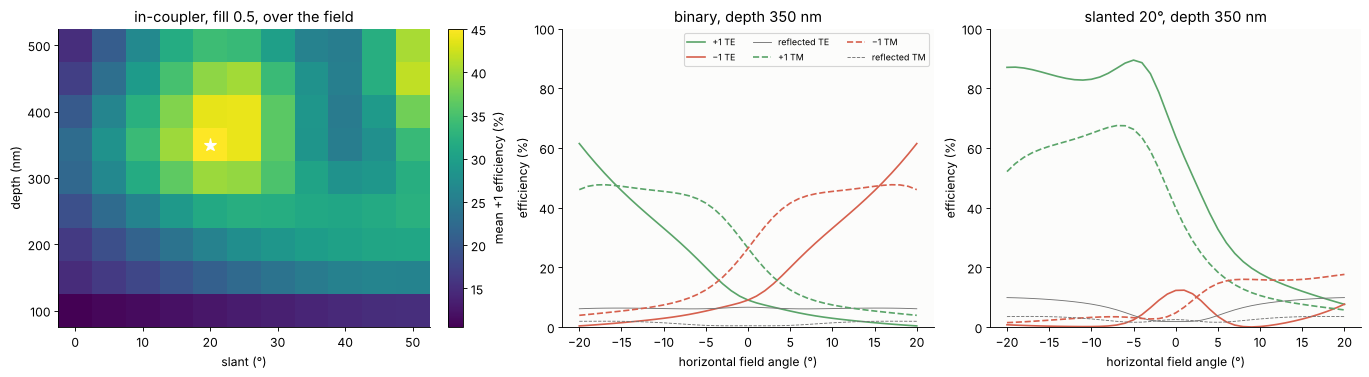

In [5]:
n_pl = n_glass["N-LASF46B"]
theta_f = np.radians(np.linspace(-20, 20, 41))
kx_f = np.sin(theta_f)


def coupler_orders(layers, pol, kx=kx_f):
    r = rcwa(P_green, layers, LAM, k_x=kx, n_in=1.0, n_out=n_pl, n_orders=12)
    jones = np.array((0, 1) if pol == "TE" else (1, 0), dtype=complex)
    R, T = r.efficiencies(jones)
    return T[:, r.m == 1].ravel(), T[:, r.m == -1].ravel(), R.sum(axis=1)


# scan slant and depth at fill 0.5 for the mean +1 efficiency (TE and TM averaged)
slants = np.radians(np.arange(0, 51, 5))
depths = np.arange(0.10, 0.51, 0.05)*1e3            # nm
scan = np.zeros((len(depths), len(slants)))
for i, dpt in enumerate(depths):
    for j, s in enumerate(slants):
        L = arvr.slanted_grating(P_green, dpt, 0.5, s, n_pl, n_slices=12)
        scan[i, j] = 0.5*(coupler_orders(L, "TE")[0].mean() + coupler_orders(L, "TM")[0].mean())
i_best, j_best = np.unravel_index(np.argmax(scan), scan.shape)
best_depth, best_slant = depths[i_best], slants[j_best]
print("best slanted grating: depth {:.0f} nm, slant {:.0f}°, mean +1 efficiency {:.1%}".format(
    best_depth, np.degrees(best_slant), scan[i_best, j_best]))
i_bin = np.argmax(scan[:, 0])
print("best binary grating:  depth {:.0f} nm, mean +1 efficiency {:.1%}".format(depths[i_bin], scan[i_bin, 0]))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
im = axs[0].pcolormesh(np.degrees(slants), depths, 100*scan, cmap="viridis", shading="nearest")
axs[0].plot(np.degrees(best_slant), best_depth, "w*", ms=12)
fig.colorbar(im, ax=axs[0], label="mean +1 efficiency (%)")
axs[0].set_xlabel("slant (°)")
axs[0].set_ylabel("depth (nm)")
axs[0].set_title("in-coupler, fill 0.5, over the field")
for ax, (name, L) in zip(axs[1:], (("binary, depth {:.0f} nm".format(depths[i_bin]),
                                     arvr.binary_grating(P_green, depths[i_bin], 0.5, n_pl)),
                                    ("slanted {:.0f}°, depth {:.0f} nm".format(np.degrees(best_slant), best_depth),
                                     arvr.slanted_grating(P_green, best_depth, 0.5, best_slant, n_pl, n_slices=24)))):
    for pol, ls in (("TE", "-"), ("TM", "--")):
        p1, m1, Rt = coupler_orders(L, pol)
        ax.plot(np.degrees(theta_f), 100*p1, color=GREEN, ls=ls, label="+1 " + pol)
        ax.plot(np.degrees(theta_f), 100*m1, color=RED, ls=ls, label="−1 " + pol)
        ax.plot(np.degrees(theta_f), 100*Rt, color=GREY, ls=ls, lw=0.8, label="reflected " + pol)
    ax.set_xlabel("horizontal field angle (°)")
    ax.set_ylabel("efficiency (%)")
    ax.set_ylim(0, 100)
    ax.set_title(name)
axs[1].legend(fontsize=8, ncol=3)
plt.show()

A symmetric binary grating sends as much light into −1 as into +1,
and −1 travels the wrong way along the plate: the mean +1 efficiency over
field and polarization stays at 23 %. A slanted grating breaks the
symmetry. The best of the scan, 350 nm deep and slanted by 20°, doubles
the mean to 45 %, with close to 90 % in TE at the negative field angles.
The price is a strong dependence on the field angle: the efficiency falls
to about 10 % at +20°, because the slant is a blaze that works best for
one direction of the light. The image would get darker from left to right;
real designs tune depth, slant and fill (or use several regions) to
flatten this, or correct it in the projector. The −1 orders and the
reflections of the slanted grating stay below 20 %.

## 4. The out-coupler and the eye box

Inside the plate, a field travels at the angle
$\theta_g = \arcsin(|\mathbf k|/n)$ and meets the out-coupling surface every

$$p = 2t\tan\theta_g$$

(`arvr.bounce_spacing()`), with $t$ the thickness of the plate. Each hit
couples out the fraction $\eta$ and makes a copy of the projector pupil
(width $D$) shifted by $p$. Two things follow.

**Uniformity along the plate.** With the same $\eta$ everywhere, the
copies decay as $(1 - \eta)^j$. Equal copies need $\eta$ to rise along
the plate, $\eta_j = 1/(N - j)$ for $N$ hits without losses
(`arvr.uniform_outcoupling()`, which also handles a loss per bounce),
e.g. 10 %, 11 %, 12.5 % … 100 % for ten copies. A surface relief grating
gets this from a depth that increases along the plate, which the
rigorous out-coupling efficiency below translates into nanometres.

**Gaps.** If $p > D$, the copies do not touch; an eye pupil (3 to 4 mm in
daylight) between two copies sees less light, and since $p$ depends on
the field angle, the image shows dark bands that move as the eye moves.
The fields at the TIR end ($\theta_g$ small) are dense, those at the
$\theta_\mathrm{max}$ end sparse. A thin plate helps, but it also needs
the projector pupil to fit through the in-coupler without the light
hitting the in-coupler again after one bounce (and being coupled back
out), which wants $p \gtrsim D$ at the in-coupler. The design walks the
line between the two.

`arvr.eyebox_efficiency()` integrates the copies over an eye pupil of
3.5 mm that moves across the eye box, 18 mm behind the plate. Every copy
travels sideways by $18\,\text{mm}\cdot\tan\theta_x$ on the way to the
eye, so the out-coupler must be larger than the eye box by
$2 \cdot 18\,\text{mm}\cdot\tan 20° = 13$ mm: here 28 mm for an eye box
of ±5 mm, with some margin. The plate is N-LASF46B with the green design of section 1, the
projector pupil $D = 3$ mm, the out-coupler starts 10 mm from the
in-coupler, and 1 % is lost per bounce. The graded efficiency is the
continuous version of $1/(N - j)$ for the central field,
$\eta(x) = p_0/(L - x + p_0)$, capped at 50 %.

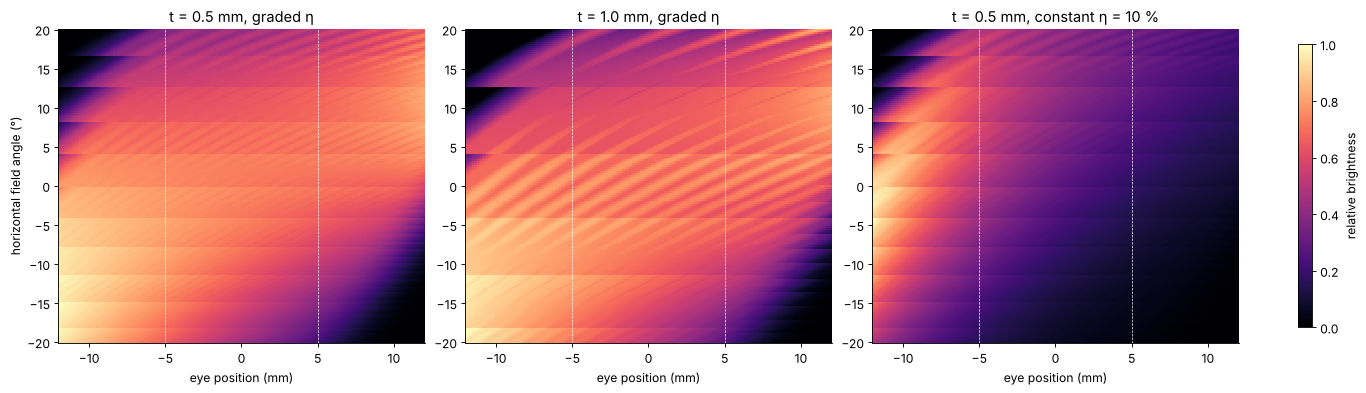

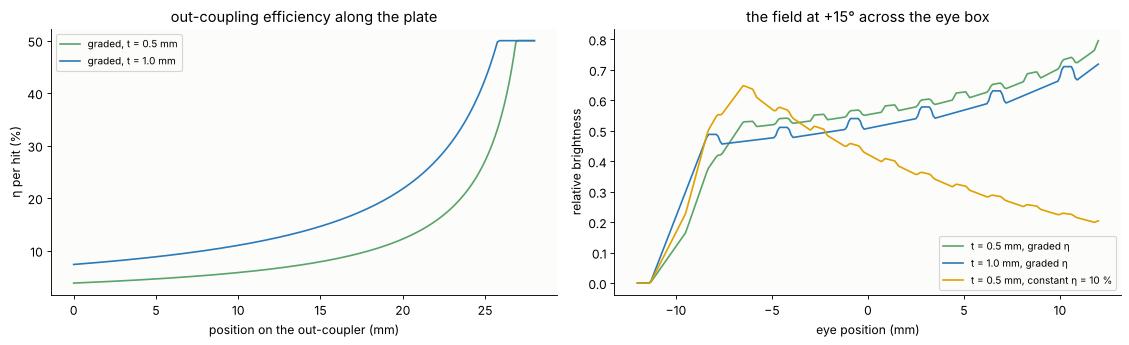

t = 0.5 mm, graded η          : spacing 0.7 to 2.4 mm; eye box ±5 mm: min/max 0.26, ripple per field 24%, mean 9.4% of the guided power in the pupil
t = 1.0 mm, graded η          : spacing 1.4 to 4.8 mm; eye box ±5 mm: min/max 0.29, ripple per field 26%, mean 9.9% of the guided power in the pupil
t = 0.5 mm, constant η = 10 % : spacing 0.7 to 2.4 mm; eye box ±5 mm: min/max 0.04, ripple per field 64%, mean 7.7% of the guided power in the pupil


In [6]:
D_PUPIL, EYE_PUPIL, EYE_RELIEF = 3.0, 3.5, 18.0
LOSS = 0.01
L_OC = 28.0                                        # length of the out-coupler (mm)
START = 10.0                                       # distance from the in-coupler (mm)
theta_h = np.radians(np.linspace(-20, 20, 161))
x_eye = np.linspace(-12, 12, 241)
k_in = np.sin(theta_h) + LAM/P_green               # guided |k| along x
th_g = np.arcsin(k_in/n_pl)


def eta_profile(x, thickness, graded=True, eta_const=0.10):
    """Out-coupling efficiency along the out-coupler (x from its start): graded for
    equal output of the central field, eta = p0/(L - x + p0), at most 0.5."""
    if not graded:
        return np.full_like(x, eta_const)
    p0 = arvr.bounce_spacing(thickness, np.arcsin((LAM/P_green)/n_pl))
    return np.minimum(p0/(L_OC - x + p0), 0.5)


def eyebox_map(thickness, graded=True):
    p = arvr.bounce_spacing(thickness, th_g)
    E = np.zeros((len(theta_h), len(x_eye)))
    for i, (th, pi_) in enumerate(zip(theta_h, p)):
        first = np.ceil(START/pi_)*pi_                         # first hit on the out-coupler
        pos = np.arange(first, START + L_OC, pi_)
        eta = eta_profile(pos - START, thickness, graded)
        powers = arvr.replicated_powers(eta, LOSS)
        # the eye box is centred on the out-coupler; each copy walks by eye_relief*tan(field)
        centre = START + L_OC/2
        E[i] = arvr.eyebox_efficiency(x_eye, EYE_PUPIL, pos - centre + EYE_RELIEF*np.tan(th),
                                      powers, D_PUPIL)
    return E, p


fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
maps = {}
for ax, (t, graded, ttl) in zip(axs, ((0.5, True, "t = 0.5 mm, graded η"), (1.0, True, "t = 1.0 mm, graded η"),
                                      (0.5, False, "t = 0.5 mm, constant η = 10 %"))):
    E, p = eyebox_map(t, graded=graded)
    maps[ttl] = (E, p)
    im = ax.pcolormesh(x_eye, np.degrees(theta_h), E/E.max(), cmap="magma", shading="auto", vmin=0, vmax=1)
    ax.axvline(-5, color="w", lw=0.6, ls="--")
    ax.axvline(5, color="w", lw=0.6, ls="--")
    ax.set_xlabel("eye position (mm)")
    ax.set_title(ttl)
axs[0].set_ylabel("horizontal field angle (°)")
fig.colorbar(im, ax=axs, label="relative brightness", shrink=0.9)
plt.show()

xe = np.linspace(0, L_OC, 200)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
axs[0].plot(xe, 100*eta_profile(xe, 0.5), color=GREEN, label="graded, t = 0.5 mm")
axs[0].plot(xe, 100*eta_profile(xe, 1.0), color=BLUE, label="graded, t = 1.0 mm")
axs[0].set_xlabel("position on the out-coupler (mm)")
axs[0].set_ylabel("η per hit (%)")
axs[0].legend(fontsize=9)
axs[0].set_title("out-coupling efficiency along the plate")
box = np.abs(x_eye) <= 5.0
for ttl, c in zip(maps, (GREEN, BLUE, ORANGE)):
    E = maps[ttl][0]
    axs[1].plot(x_eye, E[np.argmin(np.abs(theta_h - np.radians(15)))]/E.max(), color=c, label=ttl)
axs[1].set_xlabel("eye position (mm)")
axs[1].set_ylabel("relative brightness")
axs[1].set_title("the field at +15° across the eye box")
axs[1].legend(fontsize=9)
plt.show()

for ttl, (E, p) in maps.items():
    sub = E[:, box]
    ripple = np.mean([(r.max() - r.min())/r.max() for r in sub])
    print("{:30s}: spacing {:.1f} to {:.1f} mm; eye box ±5 mm: min/max {:.2f}, ripple per field {:.0%}, "
          "mean {:.1%} of the guided power in the pupil".format(
              ttl, p.min(), p.max(), sub.min()/sub.max(), ripple, sub.mean()))

The maps show brightness against eye position and field angle,
normalized to the brightest point; the dashed lines mark the ±5 mm eye
box. Three effects are visible.

- **Walk-off.** The dark corners (top left, bottom right) are fields whose
  copies have walked out of the eye box: at +20° the copies travel
  6.5 mm sideways on the way to the eye. The margin of the out-coupler
  keeps them out of the ±5 mm box.
- **Gaps.** The thick plate (1 mm, spacing up to 4.8 mm, more than the
  3 mm projector pupil) shows diagonal stripes: a 3.5 mm eye pupil
  catches one copy or two, depending on where it is. The thin plate
  (0.5 mm) has copies that touch and is smoother. The horizontal steps
  are fields at which one hit more or less falls on the out-coupler.
- **Grading.** With a constant 10 %, the copies decay along the plate and
  the far side of the eye box gets a third of the light of the near
  side or less (min/max 0.04 over field and eye box). The graded profile lifts
  this to 0.26 (0.5 mm) and 0.29 (1 mm). It is designed for the central
  field; the +15° field (right), which has fewer hits, is over-corrected
  and rises from 0.5 to 0.75 across the eye box.

The pupil collects about 10 % of the guided light in every case, since
most of the light leaves the plate outside the eye pupil: the price of a
large eye box. With the in-coupler at 45 % and some loss in the plate,
less than 5 % of the projector light reaches the eye, which is why
waveguide AR needs bright micro-LED or LCoS projectors.

**The out-coupling efficiency in nanometres.** The out-coupler sees the
guided light from inside the glass, at $k_x = \sin\theta_x + \lambda/\Lambda$,
and its order −1 returns the field to $k_x = \sin\theta_x$ in air. Placed
on the eye side of the plate, its transmitted order −1 goes to the eye.
Its reflected order −1 goes back through the plate and leaves on the world
side: the image can be seen from outside, a privacy problem known as
**eye glow**. Below, a binary out-coupler of the same period, as a
function of its depth, at the centre of the field: a shallow grating is a
weak one, and the graded efficiencies of ten equal copies (dotted) map to
depths that grow along the plate.

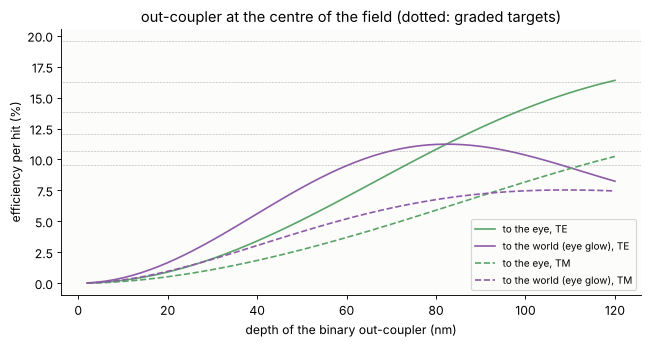

graded targets: [  9.6  10.7  12.1  13.9  16.3  19.6  24.6  33.   49.7 100. ]
  η =  9.6 %: TE depth  73.3 nm
  η = 10.7 %: TE depth  79.2 nm
  η = 12.1 %: TE depth  87.0 nm
  η = 13.9 %: TE depth  98.2 nm
  η = 16.3 %: TE depth 118.4 nm
eye glow / eye light at 40 nm (TE): 1.65


In [7]:
depth_oc = np.linspace(2, 120, 60)
k_guided = 0.0 + LAM/P_green
eta_eye, eta_world = {"TE": [], "TM": []}, {"TE": [], "TM": []}
for dpt in depth_oc:
    L = arvr.binary_grating(P_green, dpt, 0.5, n_pl)[::-1]      # light from the glass side
    r = rcwa(P_green, L, LAM, k_x=k_guided, n_in=n_pl, n_out=1.0, n_orders=12)
    for pol, j in (("TE", (0, 1)), ("TM", (1, 0))):
        R, T = r.efficiencies(np.array(j, dtype=complex))
        eta_eye[pol].append(T[0, r.m == -1][0])
        eta_world[pol].append(R[0, r.m == -1][0])
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
for pol, ls in (("TE", "-"), ("TM", "--")):
    ax.plot(depth_oc, 100*np.array(eta_eye[pol]), color=GREEN, ls=ls, label="to the eye, " + pol)
    ax.plot(depth_oc, 100*np.array(eta_world[pol]), color=PURPLE, ls=ls, label="to the world (eye glow), " + pol)
eta_targets = arvr.uniform_outcoupling(10, LOSS)
for e in eta_targets[:6]:
    ax.axhline(100*e, color=GREY, lw=0.5, ls=":")
ax.set_xlabel("depth of the binary out-coupler (nm)")
ax.set_ylabel("efficiency per hit (%)")
ax.set_title("out-coupler at the centre of the field (dotted: graded targets)")
ax.legend(fontsize=9)
plt.show()
te = np.array(eta_eye["TE"])
print("graded targets:", np.round(100*eta_targets, 1))
for e in eta_targets[:5]:
    print("  η = {:4.1f} %: TE depth {:5.1f} nm".format(100*e, np.interp(e, te, depth_oc)))
print("eye glow / eye light at 40 nm (TE): {:.2f}".format(
    np.interp(40, depth_oc, eta_world["TE"])/np.interp(40, depth_oc, eta_eye["TE"])))

The graded targets 9.6 % to 16 % map to depths of 73 nm to 118 nm
in TE: the out-coupler is a grating whose depth grows by a factor 1.6 over
the first half of the plate. The steeper end of the profile (25 % to
50 %) is out of reach for this binary profile and needs deeper, slanted
or higher-index gratings; in practice, designs cap the efficiency and
accept some light that stays in the plate. The eye glow is large: a
shallow grating sends more light to the world than to the eye (1.65
times at 40 nm), and still about as much at the depths in use. Slanted
gratings, coatings on the world side and the choice of the reflected
rather than transmitted order are the usual counter measures.

## 5. The rainbow artefact

The out-coupler works on all light, including the light of the world.
Light from a lamp or the sky reaches the out-coupler through the plate
with its own $\mathbf k_w$, $|\mathbf k_w| \le 1$, and the grating adds
$\pm\lambda/\Lambda$ to it, like for the image. If the result lands in
the unit disk, it leaves towards the eye; if it lands inside the field of
view, the wearer sees a coloured streak in the middle of the image,
because every wavelength has a different $\lambda/\Lambda$: the **rainbow
artefact**. It needs

$$|\mathbf k_w \pm \lambda/\Lambda\,\hat{\mathbf x}| < 1
\quad\text{with}\quad |\mathbf k_w| < 1,$$

so it exists only for $\lambda/\Lambda < 2$, and only for light coming
in at grazing angles along the grating vector: from the side for the
horizontal guide of this notebook, from above or below for glasses whose
guide runs vertically, where ceiling lamps and the sun are. Below, the sky seen by the out-coupler: for each direction of
the world (the hemisphere in front of the wearer, as $\mathbf k_w$),
the wavelength that the order −1 sends into the field of view. Two
designs: the N-LASF46B plate of this notebook ($\lambda/\Lambda = 1.42$ at
530 nm) and a cheaper N-BK7 plate ($\lambda/\Lambda = 1.21$).

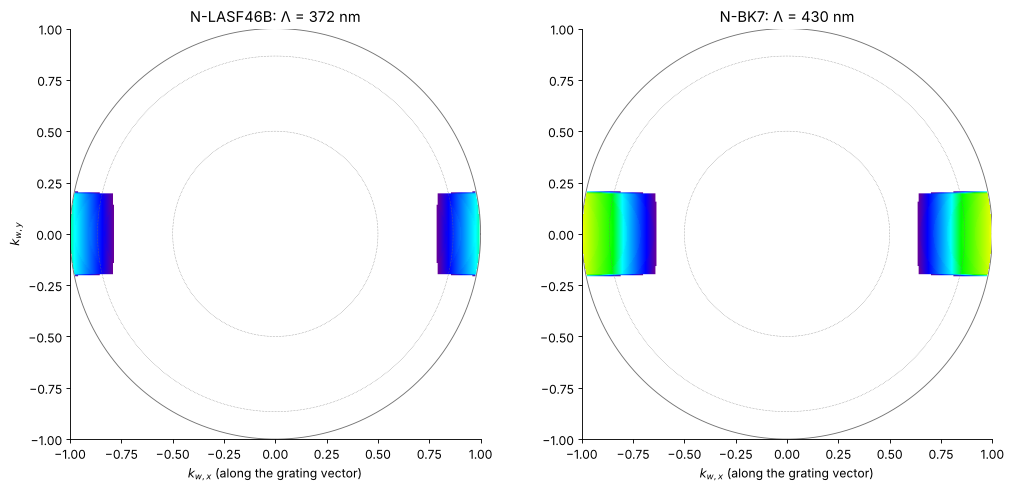

N-LASF46B : 5.2% of the world hemisphere (in k) causes a rainbow; sources at ≥ 52° from the normal
N-BK7     : 9.2% of the world hemisphere (in k) causes a rainbow; sources at ≥ 40° from the normal


In [8]:
lam_vis = np.linspace(420, 680, 131)
kw = np.linspace(-1, 1, 401)
KWX, KWY = np.meshgrid(kw, kw)
inside = KWX**2 + KWY**2 < 1


def wavelength_to_rgb(lam):
    """Rough visible colour of a wavelength (for display only)."""
    r = np.interp(lam, [420, 440, 490, 510, 580, 645, 680], [0.4, 0.0, 0.0, 0.0, 1.0, 1.0, 0.7])
    g = np.interp(lam, [420, 440, 490, 510, 580, 645, 680], [0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0])
    b = np.interp(lam, [420, 440, 490, 510, 580, 645, 680], [0.6, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0])
    return np.stack([r, g, b], axis=-1)


fig, axs = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
rainbow_stats = {}
for ax, g in zip(axs, ("N-LASF46B", "N-BK7")):
    n = n_glass[g]
    P = arvr.symmetric_period(n, LAM)
    img = np.ones(KWX.shape + (3,))
    hit = np.zeros(KWX.shape, dtype=bool)
    for lam in lam_vis:
        for m in (1, -1):
            ex, ey = arvr.diffract(KWX, KWY, P, lam, order=m)
            tx, ty = arvr.k_to_field(ex, ey)
            vis = inside & (np.abs(tx) < HFOV/2) & (np.abs(ty) < VFOV/2)
            img[vis] = wavelength_to_rgb(lam)
            hit |= vis
    ax.imshow(img, extent=(-1, 1, -1, 1), origin="lower")
    ax.plot(np.cos(phi), np.sin(phi), color=GREY, lw=0.8)
    for el in (30, 60):
        ax.plot(np.cos(np.radians(el))*np.cos(phi), np.cos(np.radians(el))*np.sin(phi),
                color=GREY, lw=0.5, ls=":")
    ax.set_xlabel("$k_{w,x}$ (along the grating vector)")
    ax.set_title("{}: Λ = {:.0f} nm".format(g, P))
    # elevation of the sources: |k_w| = cos(elevation from the plate plane)... report the angle from the normal
    if hit.any():
        ang = np.degrees(np.arcsin(np.hypot(KWX, KWY)[hit]))
        rainbow_stats[g] = (hit.sum()/inside.sum(), ang.min())
    else:
        rainbow_stats[g] = (0.0, np.nan)
axs[0].set_ylabel("$k_{w,y}$")
plt.show()
for g, (frac, amin) in rainbow_stats.items():
    print("{:10s}: {:.1%} of the world hemisphere (in k) causes a rainbow; sources at ≥ {:.0f}° from the normal".format(
        g, frac, amin))

Only light from directions near the plane of the plate and along
the grating vector reaches the field of view: for N-LASF46B, sources at
52° or more from the normal, about 5 % of the hemisphere (in k), and only
at the violet and blue end of the spectrum. The low-index N-BK7 design,
with its smaller $\lambda/\Lambda$, opens the window from 40° on, almost
twice as large, and across the visible spectrum. A high index is
therefore good for the rainbow as well; what remains can be suppressed by
an angle-selective coating on the world side, or by orienting the grating
vector so that the dangerous directions are rare (horizontal rather than
vertical guides avoid ceiling lights and the sun).

## 6. Two-dimensional pupil expansion

A single out-coupler expands the pupil along one direction only. To get
an eye box that is wide and tall from a small projector, HoloLens-type
combiners add a **fold grating** between in-coupler and out-coupler. It
is rotated by about 45° to the other two: at each hit it diffracts a
little light by 90° in the plane of the plate, which expands the pupil
along the first direction and sends the copies down, where the
out-coupler expands them along the second direction and couples them out.
For the image to leave the plate as it entered, the three grating vectors
must sum to zero; with the in-coupler and out-coupler perpendicular, the
fold grating has $|\mathbf G_\mathrm{fold}| = \sqrt 2\,|\mathbf G|$, i.e.
a period $\Lambda/\sqrt 2$, and grooves at 45°.

In k-space, the field of view now visits three places: after the
in-coupler, after the fold grating and after the out-coupler, and the
first two must both lie in the guided annulus. The two fields walk around
the annulus, which costs field of view against the 1D design, since the
fold region has to hold the field rotated by 90°. Below for N-LASF46B: the
field of view after each grating and the guided fraction against the
size of the field.

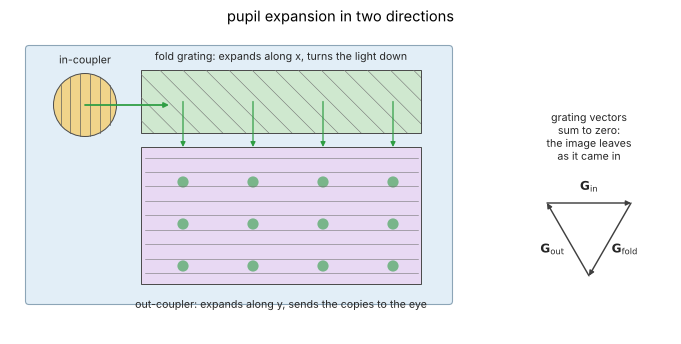

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
with sketch.text_scale(1.2):
    sketch.waveguide_combiner(ax, "epe2d", title="pupil expansion in two directions")
plt.show()

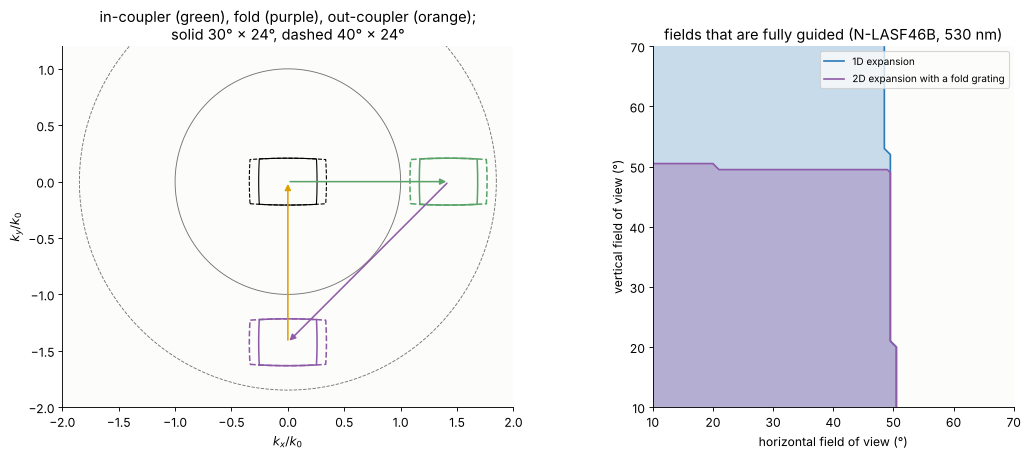

|G| = λ/Λ = 1.424 (Λ = 372 nm), fold grating Λ/√2 = 263 nm
1D: largest H 50° (V up to 70° at H = 30°); 2D: largest H 50°, largest V 50°
largest diagonal (approx., angles added in quadrature): 1D 85°, 2D 69°


In [10]:
r_max = n_pl*np.sin(THETA_MAX)
G = (1 + r_max)/2                                   # |G_in| = |G_out|
# a symmetric layout: G_in along +x, G_fold at -135°, G_out along +y (sum zero)
g_in = np.array([G, 0.0])
g_out = np.array([0.0, G])
g_fold = -(g_in + g_out)


fig, axs = plt.subplots(1, 2, figsize=(14, 5.6), layout="constrained")
ax = axs[0]
for r, ls in ((1.0, "-"), (r_max, "--")):
    ax.plot(r*np.cos(phi), r*np.sin(phi), color=GREY, lw=0.8, ls=ls)
for hf, ls in ((np.radians(30), "-"), (np.radians(40), "--")):
    bx, by = fov_box(hf, VFOV)
    ax.plot(bx, by, color="k", lw=1.0, ls=ls)
    ax.plot(bx + g_in[0], by + g_in[1], color=GREEN, lw=1.4, ls=ls)
    ax.plot(bx + g_in[0] + g_fold[0], by + g_in[1] + g_fold[1], color=PURPLE, lw=1.4, ls=ls)
for start, vec, c in (((0, 0), g_in, GREEN), (tuple(g_in), g_fold, PURPLE), (tuple(g_in + g_fold), g_out, ORANGE)):
    ax.annotate("", xy=(start[0] + vec[0], start[1] + vec[1]), xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.4))
ax.set_aspect("equal")
ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-2.0, 1.2)
ax.set_xlabel("$k_x/k_0$")
ax.set_ylabel("$k_y/k_0$")
ax.set_title("in-coupler (green), fold (purple), out-coupler (orange);\n"
             "solid 30° × 24°, dashed 40° × 24°")
ax = axs[1]
hv = np.radians(np.linspace(10, 70, 61))
full1 = np.zeros((len(hv), len(hv)), dtype=bool)
full2 = np.zeros_like(full1)
for i, v in enumerate(hv):
    for j, h in enumerate(hv):
        tx, ty = np.meshgrid(np.linspace(-h/2, h/2, 25), np.linspace(-v/2, v/2, 25))
        kx, ky = arvr.field_to_k(tx, ty)
        k1 = (kx + g_in[0], ky + g_in[1])
        k2 = (k1[0] + g_fold[0], k1[1] + g_fold[1])
        g1 = arvr.is_guided(*k1, n_pl, THETA_MAX)
        full1[i, j] = g1.all()
        full2[i, j] = (g1 & arvr.is_guided(*k2, n_pl, THETA_MAX)).all()
H, V = np.meshgrid(np.degrees(hv), np.degrees(hv))
ax.contourf(H, V, full1.astype(float), levels=[0.5, 1.5], colors=[BLUE], alpha=0.25)
ax.contour(H, V, full1.astype(float), levels=[0.5], colors=[BLUE])
ax.contourf(H, V, full2.astype(float), levels=[0.5, 1.5], colors=[PURPLE], alpha=0.35)
ax.contour(H, V, full2.astype(float), levels=[0.5], colors=[PURPLE])
ax.plot([], [], color=BLUE, label="1D expansion")
ax.plot([], [], color=PURPLE, label="2D expansion with a fold grating")
ax.set_xlabel("horizontal field of view (°)")
ax.set_ylabel("vertical field of view (°)")
ax.set_title("fields that are fully guided (N-LASF46B, 530 nm)")
ax.set_aspect("equal")
ax.legend(fontsize=9)
plt.show()
diag1 = max(np.degrees(np.hypot(h, v)) for (i, j), ok in np.ndenumerate(full1) if ok for h, v in [(hv[j], hv[i])])
diag2 = max(np.degrees(np.hypot(h, v)) for (i, j), ok in np.ndenumerate(full2) if ok for h, v in [(hv[j], hv[i])])
print("|G| = λ/Λ = {:.3f} (Λ = {:.0f} nm), fold grating Λ/√2 = {:.0f} nm".format(G, LAM/G, LAM/G/np.sqrt(2)))
print("1D: largest H {:.0f}° (V up to {:.0f}° at H = 30°); 2D: largest H {:.0f}°, largest V {:.0f}°".format(
    H[full1].max(), V[:, np.argmin(np.abs(hv - np.radians(30)))][full1[:, np.argmin(np.abs(hv - np.radians(30)))]].max(),
    H[full2].max(), V[full2].max()))
print("largest diagonal (approx., angles added in quadrature): 1D {:.0f}°, 2D {:.0f}°".format(diag1, diag2))

With $|\mathbf G| = 1.42$ (period 372 nm) and a fold grating of
263 nm, the fold region bounds the vertical field: the 2D design guides
up to about 50° × 50°, while the 1D design keeps its horizontal limit
of 50° and is not limited vertically within this scan (up to 70°).
Measured on the diagonal, which is what data sheets quote, the fold
grating costs about 15° (85° against 69°, as a rough estimate with the
angles added in quadrature). In return, the projector pupil needs to be
only a few millimetres in both directions, which keeps the projector
small. All commercial 2D combiners (HoloLens, Magic Leap) take this
trade.

## Summary

- The field of view of a waveguide combiner is a rectangle in k-space that
  the in-coupler has to fit into the annulus between the TIR circle 1 and
  $n\sin\theta_\mathrm{max}$. The index of the plate sets the field of
  view; glass at $n = 1.9$ to 2.0 and silicon carbide at 2.6 are the
  reason for the growth of the field of view in recent products.
- The grating vector scales with the wavelength, so the field shifts with
  the colour; full colour over a large field needs one plate per primary
  or a compromise in uniformity.
- Surface relief in-couplers are close to the wavelength in period and
  need rigorous modelling; slanted ridges send most light one way.
- The out-coupler replicates the pupil at the bounce spacing $2t\tan\theta_g$;
  graded efficiencies make the copies equal, thin plates close the gaps
  between them. The depth of the out-coupler is the knob, and part of
  the light leaks out on the world side.
- The out-coupler diffracts world light too; grazing light along the grating vector
  reaches the eye as a rainbow, more so for low-index plates with longer
  periods.
- A fold grating expands the pupil in two directions and needs grating
  vectors that sum to zero, at a cost in field of view.

## References

- B. C. Kress, *Optical Architectures for Augmented-, Virtual-, and
  Mixed-Reality Headsets*, SPIE Press (2020).
- B. C. Kress and W. J. Cummings, "Towards the ultimate mixed reality
  experience: HoloLens display architecture choices", SID Symp. Dig. 48,
  127–131 (2017).
- T. Levola, "Diffractive optics for virtual reality displays", J. Soc.
  Inf. Disp. 14, 467–475 (2006).
- J. Xiong, E.-L. Hsiang, Z. He, T. Zhan and S.-T. Wu, "Augmented reality
  and virtual reality displays: emerging technologies and future
  perspectives", Light Sci. Appl. 10, 216 (2021).
- M. G. Moharam, D. A. Pommet, E. B. Grann and T. K. Gaylord, "Stable
  implementation of the rigorous coupled-wave analysis for surface-relief
  gratings", J. Opt. Soc. Am. A 12, 1077–1086 (1995).

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 150 s
